# Pliegues estrictos frente a pliegues con fuga y los controles: dónde tiene habilidad la columna vertebral y dónde no

**Pregunta:** ¿Para cuál de los dos objetivos medidos supera la columna vertebral retenida a la línea base de media constante y al control de barajado, y con qué frecuencia la supera por azar un control preregistrado?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el notebook 01 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este notebook usted puede:

- medir el optimismo del juicio dentro de la muestra para el tonelaje y para la potencia, modelo por modelo;
- aplicar la línea base de media constante y decir para qué objetivo la supera la columna vertebral;
- correr el control de barajado con muchas semillas, no con una, y leer con qué frecuencia supera a la columna vertebral;
- leer el modelo de residuo acotado como el nulo preregistrado que es, y el resultado de potencia como un negativo honesto.

## Preparación

Numpy y matplotlib.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

Las importaciones son los mismos dos constructores del notebook 01.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.hp500.surveys import read_surveys
from pipeline.hp500 import backbone, loo
from pipeline.model.crusher.capacity import HP500_QREF
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Los diez muestreos del HP500 y los documentos versionados derivados de ellos. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivos leídos: `data/examples/hp500-surveys.csv`, `data/derived/hp500/backbone.json` y `data/derived/hp500/loo.json`.

La celda lee los archivos y reconstruye en vivo el documento de CrusherCal, como en el notebook 01.

In [2]:
# Reconstruya en vivo la columna vertebral y el documento de CrusherCal desde la tabla de muestreos; deben ser los versionados
surveys = read_surveys().accepted
version = json.loads((ROOT / "data" / "derived" / "hp500" / "backbone.json").read_text(encoding="utf-8"))["engine_version"]
live_backbone = backbone.build(surveys, version)
doc = loo.build(live_backbone, version)
committed = json.loads((ROOT / "data" / "derived" / "hp500" / "loo.json").read_text(encoding="utf-8"))
print("el documento de CrusherCal reconstruido es igual al versionado:", doc == committed, "| muestreos:", doc["n"])

el documento de CrusherCal reconstruido es igual al versionado: True | muestreos: 10


## Método

**Paso 1, el optimismo en los dos objetivos.** Los dos objetivos medidos son el tonelaje en t/h y la potencia en kW; el tamaño del producto es una salida del modelo, así que se juzga solo por autoconsistencia. La celda lista, para cada modelo y cada objetivo, el MAPE retenido y el de dentro de la muestra y su diferencia. La figura dibuja la diferencia, el optimismo, como barras: mientras más alta la barra, más adulaba el número dentro de la muestra al modelo.

In [3]:
# MAPE retenido y dentro de la muestra de los cuatro modelos para ambos objetivos, y su diferencia
names = ("M0_backbone", "M1_residual", "M2_freeform", "constant_mean")
gap = {}
for key in ("tph", "kW"):
    block = doc["loo"][key]
    for m in names:
        a, b = block["strict"][m]["mape_pct"], block["leaky"][m]["mape_pct"]
        gap[(key, m)] = a - b
        print(f"{key:4s} {m:14s} retenido {a:6.2f} %  dentro de la muestra {b:6.2f} %  optimismo {a - b:+6.2f}")

tph  M0_backbone    retenido  12.09 %  dentro de la muestra  10.95 %  optimismo  +1.14
tph  M1_residual    retenido  13.45 %  dentro de la muestra   8.51 %  optimismo  +4.94
tph  M2_freeform    retenido  12.18 %  dentro de la muestra   8.24 %  optimismo  +3.94
tph  constant_mean  retenido  18.29 %  dentro de la muestra  16.46 %  optimismo  +1.83
kW   M0_backbone    retenido  25.94 %  dentro de la muestra  19.28 %  optimismo  +6.66
kW   M1_residual    retenido  25.37 %  dentro de la muestra  12.00 %  optimismo +13.37
kW   M2_freeform    retenido  14.03 %  dentro de la muestra   9.46 %  optimismo  +4.57
kW   constant_mean  retenido  24.48 %  dentro de la muestra  22.03 %  optimismo  +2.45


La figura dibuja el optimismo de cada modelo como una barra, un par por modelo.

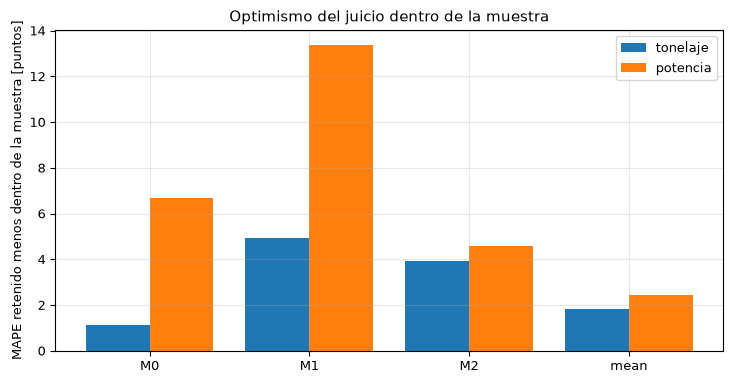

In [4]:
# Gráfico de barras del optimismo de cada modelo para el tonelaje y para la potencia
fig, ax = plt.subplots()
x = np.arange(len(names))
ax.bar(x - 0.2, [gap[("tph", m)] for m in names], 0.4, label="tonelaje")
ax.bar(x + 0.2, [gap[("kW", m)] for m in names], 0.4, label="potencia")
ax.set_xticks(x, [m.split("_")[0] if m != "constant_mean" else "mean" for m in names])
ax.set_ylabel("MAPE retenido menos dentro de la muestra [puntos]")
ax.set_title("Optimismo del juicio dentro de la muestra")
ax.legend()
fig.tight_layout()
plt.show()

Para el tonelaje la columna vertebral, con un escalar ajustado, tiene el menor optimismo de los cuatro, 1,1 puntos, y M1, con su residuo ridge, el mayor, 4,9. Para la potencia el optimismo es mayor en todos los modelos: 6,7 puntos para la columna vertebral, cuya forma de potencia tiene dos coeficientes reajustados con un óptimo dentro de la muestra de signo equivocado (notebook 03 del tema 05), 13,4 para M1, y 4,6 para la regresión sin restricciones, cuyo error retenido ya es bajo. La línea base de media constante, que no tiene más parámetro ajustado que la media, muestra de todos modos 1,8 y 2,5 puntos, un recordatorio de que la línea base no está exenta: incluso una media se ajusta con una muestra. La figura dice cuánto hay que descontar cada número dentro de la muestra, y no qué modelo gana; para eso hacen falta los propios valores retenidos, que vienen a continuación.

**Paso 2, la línea base.** La habilidad es el error retenido relativo al de la línea base: un modelo debe quedar bajo la media constante para reclamarla. La celda imprime, para cada objetivo, el MAPE retenido de la columna vertebral, el de la línea base y la reducción relativa. Una reducción negativa significa que el modelo es peor que adivinar el promedio.

In [5]:
# Reducción relativa del error retenido de la columna vertebral frente a la línea base de media constante, por objetivo
for key, label in (("tph", "tonelaje"), ("kW", "potencia")):
    strict = doc["loo"][key]["strict"]
    backbone_error, baseline_error = strict["M0_backbone"]["mape_pct"], strict["constant_mean"]["mape_pct"]
    print(f"{label:10s} columna vertebral {backbone_error:6.2f} %   línea base {baseline_error:6.2f} %   reducción {(baseline_error - backbone_error) / baseline_error * 100:+6.1f} %")

tonelaje   columna vertebral  12.09 %   línea base  18.29 %   reducción  +33.9 %
potencia   columna vertebral  25.94 %   línea base  24.48 %   reducción   -6.0 %


**Paso 3, el control con muchas semillas.** El control de barajado ajusta el modelo de residuo a mediciones permutadas: si resultara tan bueno como la columna vertebral, la habilidad aparente del modelo de residuo sería una fuga. El documento versionado contiene un barajado, con una semilla, y con diez puntos un sorteo dice poco, como mostró el notebook 03 del tema 05. La celda reconstruye el documento con 200 semillas distintas y registra el error retenido del modelo barajado cada vez, para ambos objetivos, y cuenta las semillas en que supera a la columna vertebral. La corrida del pipeline toma una fracción de segundo por semilla.

In [6]:
# Reconstruya CrusherCal con 200 semillas y registre el error retenido del control de barajado para ambos objetivos
shuffle = {"tph": [], "kW": []}
for seed in range(1, 201):
    other = loo.build(live_backbone, version, seed=seed)["loo"]
    for key in shuffle:
        shuffle[key].append(other[key]["strict"]["M1_label_shuffle"]["mape_pct"])
for key in shuffle:
    values = np.array(shuffle[key])
    reference = doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"]
    print(f"{key:4s} control de barajado: media {values.mean():6.2f} %, min {values.min():6.2f} %, max {values.max():6.2f} %  |  semillas que superan a la columna vertebral: {int((values < reference).sum())} de 200")

tph  control de barajado: media  18.36 %, min  10.45 %, max  25.76 %  |  semillas que superan a la columna vertebral: 5 de 200
kW   control de barajado: media  32.19 %, min  19.08 %, max  42.00 %  |  semillas que superan a la columna vertebral: 21 de 200


La figura muestra los 200 errores barajados del tonelaje como un histograma, con el error retenido de la columna vertebral como una línea vertical. Un control hace su trabajo cuando su distribución queda bien a la derecha de la línea del modelo.

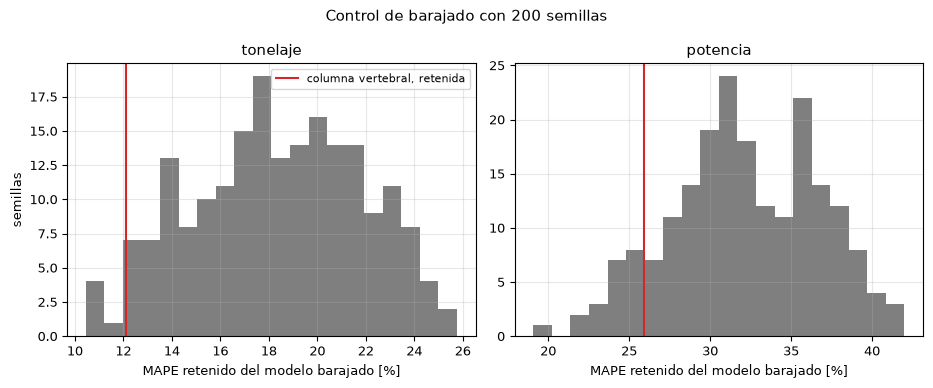

In [7]:
# Histograma del error del control de barajado con 200 semillas, para cada objetivo, frente al error retenido de la columna vertebral
fig, (left, right) = plt.subplots(1, 2, figsize=(9.4, 3.9))
for ax, key, label in ((left, "tph", "tonelaje"), (right, "kW", "potencia")):
    ax.hist(shuffle[key], bins=20, color="tab:grey")
    ax.axvline(doc["loo"][key]["strict"]["M0_backbone"]["mape_pct"], color="tab:red", lw=1.5, label="columna vertebral, retenida")
    ax.set_xlabel("MAPE retenido del modelo barajado [%]")
    ax.set_title(label)
left.set_ylabel("semillas")
left.legend(fontsize=8)
fig.suptitle("Control de barajado con 200 semillas")
fig.tight_layout()
plt.show()

Para el tonelaje la línea de la columna vertebral queda en el extremo izquierdo del histograma: solo 5 de las 200 semillas producen un modelo barajado igual de preciso (2,5 por ciento), así que la habilidad de la columna vertebral no es una fuga. Para la potencia la línea queda dentro del histograma, con 21 de 200 semillas (10,5 por ciento) que lo hacen al menos igual de bien, que es como se ve la ausencia de habilidad. Los dos histogramas juntos son la razón de correr el control con muchas semillas: un sorteo con la semilla versionada (25,04 y 40,19 por ciento) habría pasado ambos objetivos, y la distribución dice que debería pasar solo uno.

**Paso 4, el modelo de residuo y el tamaño del producto.** El residuo ridge acotado M1 se preregistró con la expectativa de que daría una mejora marginal o nula sobre la columna vertebral, y de que un nulo se informaría. La celda imprime M1 frente a M0 con datos retenidos para ambos objetivos. El mismo documento puntúa el tamaño del producto P80, que es una salida del modelo y no una medición; su error retenido para la columna vertebral es cero por construcción, y la celda lo muestra para que nadie lo lea como habilidad.

In [8]:
# MAPE retenido del modelo de residuo frente a la columna vertebral para ambos objetivos, y la autoconsistencia de P80
for key in ("tph", "kW"):
    strict = doc["loo"][key]["strict"]
    print(f"{key:4s} M0 {strict['M0_backbone']['mape_pct']:6.2f} %   M1 {strict['M1_residual']['mape_pct']:6.2f} %   M1 menos M0 {strict['M1_residual']['mape_pct'] - strict['M0_backbone']['mape_pct']:+5.2f}")
print("P80, MAPE retenido de la columna vertebral:", doc["loo"]["p80"]["strict"]["M0_backbone"]["mape_pct"], "%")

tph  M0  12.09 %   M1  13.45 %   M1 menos M0 +1.36
kW   M0  25.94 %   M1  25.37 %   M1 menos M0 -0.57
P80, MAPE retenido de la columna vertebral: 0.0 %


## Resultados

**Respuesta:** la columna vertebral retenida supera a la línea base de media constante para el tonelaje, 12,09 frente a 18,29 por ciento, una reducción de 33,9 por ciento, y no la supera para la potencia, 25,94 frente a 24,48 por ciento, 6 por ciento peor que adivinar el promedio. El control de barajado con 200 semillas supera a la columna vertebral en 5 semillas para el tonelaje (2,5 por ciento) y en 21 semillas para la potencia (10,5 por ciento), de modo que la habilidad del tonelaje no es una fuga y la de la potencia no existe. El modelo de residuo no supera a la columna vertebral en tonelaje, 13,45 frente a 12,09 por ciento, y es marginalmente mejor en potencia, 25,37 frente a 25,94, que tampoco es habilidad. Dentro de la muestra, el optimismo es 1,14 puntos para la columna vertebral del tonelaje y 6,66 para la de la potencia.

La primera figura muestra el optimismo y la segunda la distribución del control. Un validador concluiría que la afirmación de tonelaje del producto se sostiene y la de potencia no, que es lo que el producto informa; que una semilla de un control no es un control; y que el error retenido de potencia de la regresión sin restricciones, 14,03 por ciento, es menor que el de cualquier modelo con física, un hallazgo para el que el producto no reclama un uso: la potencia medida sigue a la abertura, lo que una regresión sobre la abertura captura y un consumo de Bond no.

## Resumen

La comparación con datos retenidos separa los dos objetivos: la columna vertebral del tonelaje tiene una habilidad que supera a una línea base y a un control corrido las veces suficientes para significar algo; la de la potencia no tiene ninguna, y la regresión sin restricciones lo hace mejor porque lee la abertura. Los números descansan en diez muestreos, y la propia dispersión del control de barajado muestra qué tan grueso es eso. El último notebook del tema enuncia la afirmación del producto más allá del estado del arte y la mide, incluida una prueba de robustez sobre subconjuntos y la calibración de una banda predictiva.

## Referencias

- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919